# IS 4487 Assignment 5: Exploratory Data Analysis (EDA) with Stakeholder Framing

In this assignment, you will:
- Load and explore a hotel bookings dataset
- Identify stakeholder needs and frame your analysis around business goals
- Practice data summarization and visualization
- Draw insights that could lead to actionable business recommendations

## Why This Matters

These skills are essential for business majors and minors working in areas like marketing, operations, finance, or consulting. Understanding how to explore and communicate data-driven insights helps you make better decisions and contribute to real-world business outcomes.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_05_eda.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.


## 1. Setup and Data Loading

Instructions:
- Import `pandas`, `seaborn`, and `matplotlib.pyplot`.
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows to confirm it loaded correctly.


In [11]:
# Your code to import libraries and load data goes here
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Stakeholder and Business Context

### Business framing:  

Every analysis should serve a decision-maker. Before you explore the data, identify who cares about hotel booking behavior and what they might want to know. Your analysis should be framed around those needs.

### Reflection:
1. Who are the key stakeholders for this dataset?
2. What goals might each stakeholder have?
3. What is a clear, specific business problem statement that this data can help answer?





### ✍️ Your Response: 🔧
1. Stakeholders that care about hotel booking behaviors could be hotel employees, hotel managers, and hotel owners.

2. Each stakeholder has different goals. Owners are looking ultimately to turn profits. For that to happen hotels need to stay booked, which is likely the goal of the hotel manager. Regular hotel employees should know booking behavior to understand supply and demand shifts so they can best help customers during critical periods.

3. "City Hotel and Resort Hotel lose revenue when bookings are canceled. Which variables are most associated with cancellations and how can management teams use this to adjust pricing or policies to help protect revenue."




## 3. Explore Data Structure and Quality

### Business framing:  

Before diving into analysis, analysts need to understand the shape and health of the data. Bad data leads to bad decisions.

### Do the following:
- Perform the following 3 checks to see the data quality:
  - Summary the data (e.g., `.info()`, `.describe()`)
  - Find the number of Null values
  - Find the number of duplicate row checks


In [12]:
# Add code here 🔧
print("Shape (rows, columns):", df.shape)
print()
df.info()
print()
df.describe()

Shape (rows, columns): (119390, 32)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 no

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [13]:
null_counts = df.isnull().sum()
null_counts = null_counts[null_counts > 0].sort_values(ascending=False)

print("Columns with null values:")
print(null_counts)
print()
print("Total null values:", df.isnull().sum().sum())

Columns with null values:
company     112593
agent        16340
country        488
children         4
dtype: int64

Total null values: 129425


In [14]:
num_duplicates = df.duplicated().sum()
print("Number of duplicate rows:", num_duplicates)

Number of duplicate rows: 31994


### Reflection:
1. Name at least one structure issue you’ve found (e.g., missing values, formatting problems).
2. How can you fix this structural issue?

### ✍️ Your Response: 🔧
1. First we found that the company column had over 112 thousand null values. This seems to be intentional, meaning that the booking wasn't made through a business. We also see significant null values in the agent column.

2. Since the company column is extremely empty, we can drop it entirely, with 94% missing/null, this variable carries little weight anyway.



## 4. Univariate Analysis

### Business framing:  

Hotels care about trends like average stay length, customer mix, and pricing. A good EDA starts with understanding single variables and their distribution.

### Do the following:
- Select at least 3 individual variables to explore
- Use plots and summary methods (e.g. info(), describe(), etc)  to describe the distribution (hint: we are only looking at the values of one variable, so think of plots you've used in the past that DON'T compare 2 variables.)
- Focus on what matters from a business standpoint (e.g., pricing, cancellations, guest types)

is_canceled
0    75166
1    44224
Name: count, dtype: int64

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


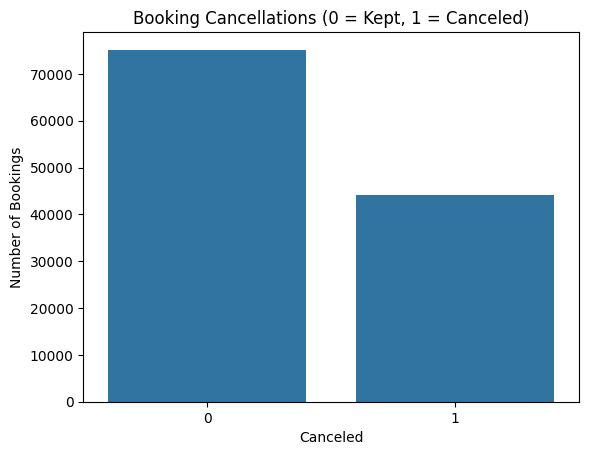

In [15]:
# Your code for univariate analysis (e.g., plots, value counts) 🔧
print(df['is_canceled'].value_counts())
print()
print(df['is_canceled'].value_counts(normalize=True).round(3))

sns.countplot(x='is_canceled', data=df)
plt.title("Booking Cancellations (0 = Kept, 1 = Canceled)")
plt.xlabel("Canceled")
plt.ylabel("Number of Bookings")
plt.show()

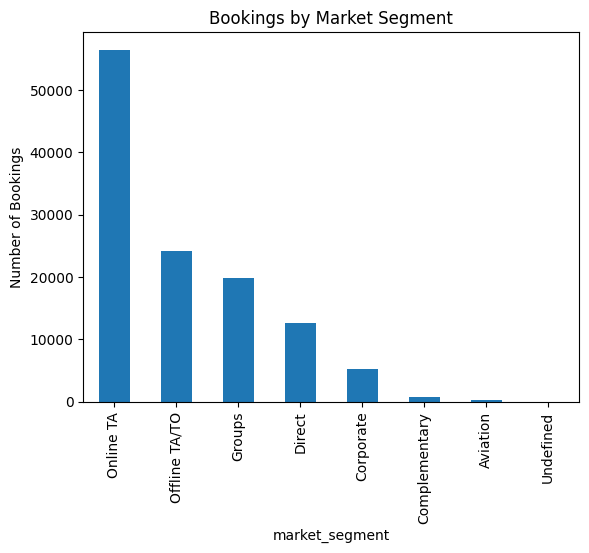

In [16]:
df['market_segment'].value_counts().plot(kind='bar', title="Bookings by Market Segment")
plt.ylabel("Number of Bookings")
plt.show()

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

hotel
City Hotel      0.664
Resort Hotel    0.336
Name: proportion, dtype: float64


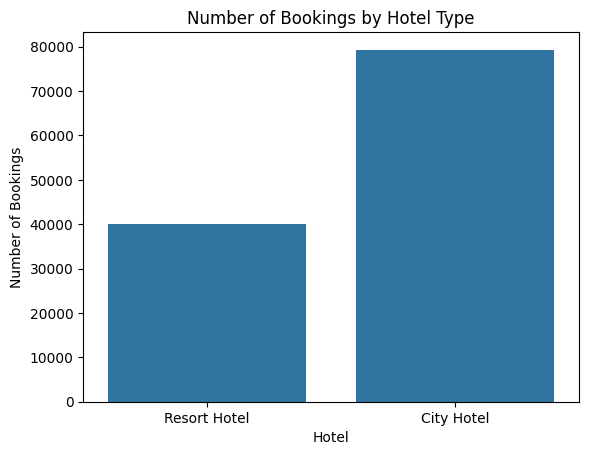

In [17]:
print(df['hotel'].value_counts())
print()
print(df['hotel'].value_counts(normalize=True).round(3))

sns.countplot(x='hotel', data=df)
plt.title("Number of Bookings by Hotel Type")
plt.xlabel("Hotel")
plt.ylabel("Number of Bookings")
plt.show()

### Reflection:
1. Variable 1 – What did you explore and what did you find?
2. Variable 2 – What did you explore and what did you find?
3. Variable 3 – What did you explore and what did you find?

### ✍️ Your Response: 🔧
- **Variable 1 – Summary and insights:**  I looked at cancellations and found that around 30-35% of bookings were cancelled, which seemed extremely high.
- **Variable 2 – Summary and insights:**  I looked at bookings by segment and I found that roughly 50%+ of booking were made through Online TA, other significant segments were Offline TA, Groups, and Direct.
- **Variable 3 – Summary and insights:**  I looked at bookings by hotel type of which there were only two. I found that roughly 77k bookings were made for the city hotel, and 40k for the resort hotel, which almost comes out to a perfect 60/40 spliot between the two.


## 5. Bivariate Analysis

### Business framing:  

Stakeholders often ask: “What drives cancellations?” or “Do longer stays mean higher revenue?” Bivariate analysis helps you uncover those kinds of relationships.

### Do the following:
- Choose 2 relevant variable pairs (e.g., `lead_time` vs. `is_canceled`, or `adr` vs. `customer_type`)
- Use scatterplots, grouped bar plots, or boxplots to explore the relationships
- Interpret what these relationships could mean for the hotel business

               count        mean         std  min   25%    50%    75%    max
is_canceled                                                                 
0            75166.0   79.984687   91.109888  0.0   9.0   45.0  124.0  737.0
1            44224.0  144.848815  118.624829  0.0  48.0  113.0  214.0  629.0


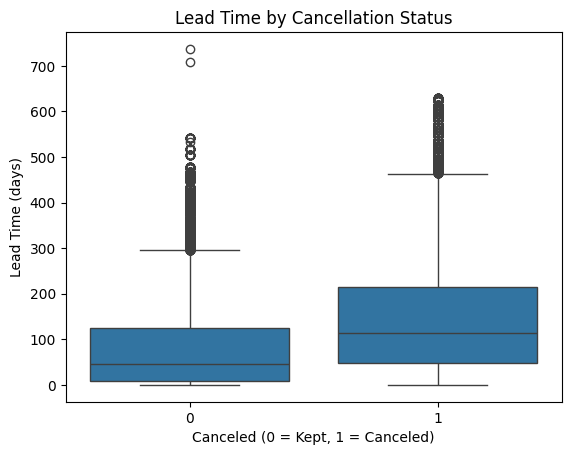

In [18]:
# Your code to analyze variable relationships (e.g., scatterplots, grouped bars) 🔧
print(df.groupby('is_canceled')['lead_time'].describe())

sns.boxplot(x='is_canceled', y='lead_time', data=df)
plt.title("Lead Time by Cancellation Status")
plt.xlabel("Canceled (0 = Kept, 1 = Canceled)")
plt.ylabel("Lead Time (days)")
plt.show()

hotel
City Hotel      41.7
Resort Hotel    27.8
Name: is_canceled, dtype: float64


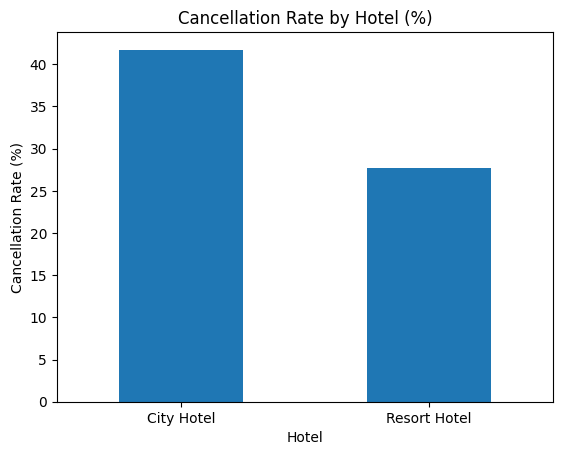

In [20]:
cancel_rate = df.groupby('hotel')['is_canceled'].mean() * 100
print(cancel_rate.round(1))

cancel_rate.plot(kind='bar', title="Cancellation Rate by Hotel (%)")
plt.xlabel("Hotel")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Reflection:
1. Relationship 1 – What did you analyze and what insights did you find?
2. Relationship 2 – What did you analyze and what insights did you find?

### ✍️ Your Response: 🔧
- **Relationship 1:**  Bookings with longer lead times were more likely to be cancelled. The median for kept bookings were around 50 days whereas cancelled bookings the median was around 100 days.
- **Relationship 2:**  I analyzed the cancellation rate for both hotels. I found that the city hotel has a significantly higher cancellation rate compared to the resort hotel, roughly 45% compared to 27%. Both of these seem high to me, even the lower being 27%, 1 in 4 bookings cancelling, this just may be a much more common thing than I've anticipated.

## 6. Problem Complexity and Analytics Framing

### Business framing:  

Let’s say you found a strong trend — maybe high lead times predict cancellations, or certain channels bring repeat guests. What kind of problem is this?

- Choose one insight from your earlier analysis
- Reflect on:
  - What type of complexity this problem represents (e.g., variety, volume, variability)
  - What kind of analytics would help solve or explain it (descriptive, diagnostic, predictive, prescriptive)

### Reflection:
1. What was your selected insight?
2. What kind of complexity does it involve?
3. What type of analytics would help, and why?



### ✍️ Your Response: 🔧
1. Bookings with higher lead times had a higher chance of being cancelled. The graph showed that the median lead times of cancelled bookings were at least double that of kept bookings.
2. This problem represents variability. The lead times ranged from 0 to over 700 days. Most bookings clustered within 200 days but some extending. Some guests booked one day in advance where other booked over a year in advance. Longer lead time bookings carry higher cancellation risk, the behavior is highly unpredictable making it difficult to accurately forecast.
3. Predictive analytics would help the most because we could use variables that we track to create a model to then predict which bookings are most likely to cancel. This could help forecast true availability and demand and help make management decisions.



## 7. Final Takeaways and Recommendations

### Business framing:  

Imagine you’re preparing for a stakeholder meeting. What would you highlight from your findings?

### Reflection:
- 1. What patterns or trends stood out?
- 2. How do they connect to stakeholder goals?
- 3. What recommendation would you make based on this analysis?
- 4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. A few patterns that stood out were that cancelled bookings has much longer median lead times, the City Hotel had a significantly higher cancellation rate than the Resort Hotel, and about a third of all bookings cancel.

2. This connects to stakeholder goals because the ultimate goal of a business, in this case a hotel, is to turn a profit. Cancelled bookings mean rooms go empty, it also means that estimated revenue is likely inflated, they likely often expect to receive more than they end up receiving. Managers need to know which variables are most closely related to cancelled bookings so they can adjust decisions to mitigate the issue.

3. One recommendation would be to require deposits on riskier bookings. Riskier bookings would generally entail longer lead-time bookings, ones that are statistically more likely to cancel. Another measure might be to begin anticipating cancellations and overbooking the hotel, this option carries more risk.

4. This relates to my career learning outcomes of be able to leverage skills like Python for auditing purposes by showing me how I can visualize data. I can learn to use Python to manipulate financial data to see if it truly matches what it should and allowing me to give my opinion on it. This could be anything from checking null values in data to visualizing sales revenue data.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_05_eda.ipynb"